# Chapter 3

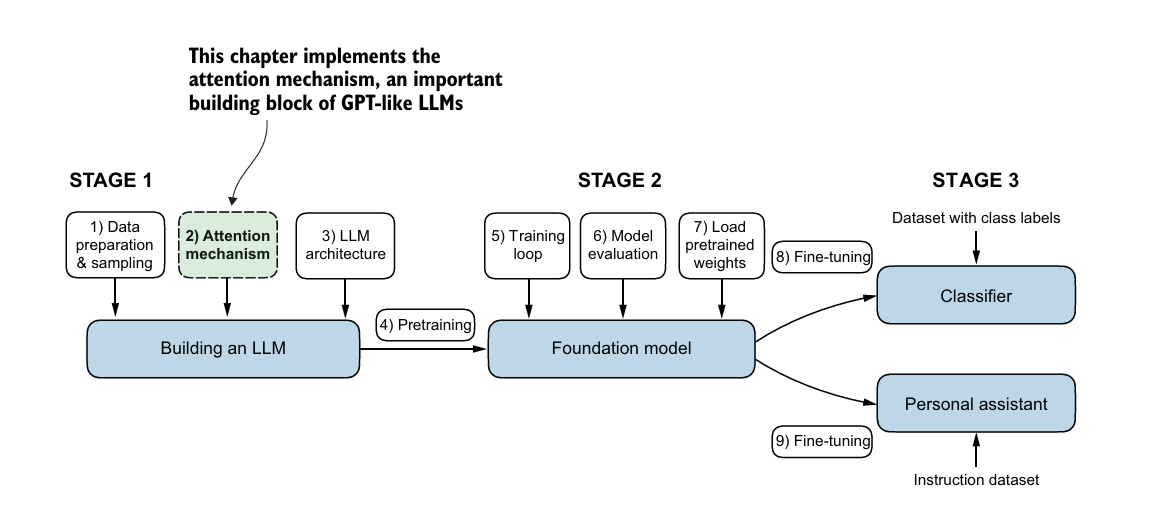

In [2]:
import torch 
inputs = torch.tensor( [
   [0.43, 0.15, 0.89],
   [0.55, 0.87, 0.66], 
   [0.57, 0.85, 0.64], 
   [0.22, 0.58, 0.33],     
   [0.77, 0.25, 0.10],      
   [0.05, 0.80, 0.55]]     
)

In [3]:
query = inputs[1]
attn_score_2 = torch.empty(inputs.shape[0])
for i,x_i in enumerate(inputs):
    attn_score_2[i] = torch.dot(x_i , query)
print(attn_score_2)


tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [4]:
def sofmax_naive(x): 
    return torch.exp(x)/torch.exp(x).sum(dim=0)

attn_score_2_naive = sofmax_naive(attn_score_2)
attn_score_2_torch = torch.softmax(attn_score_2, dim=0)
print(f"Attention weights {attn_score_2_naive}")
print(f"Sum is (Naive) {sum(attn_score_2_naive)}")  
print(f"Sum is (Pytorch)) {sum(attn_score_2_torch)}")  


Attention weights tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum is (Naive) 1.0000001192092896
Sum is (Pytorch)) 1.0


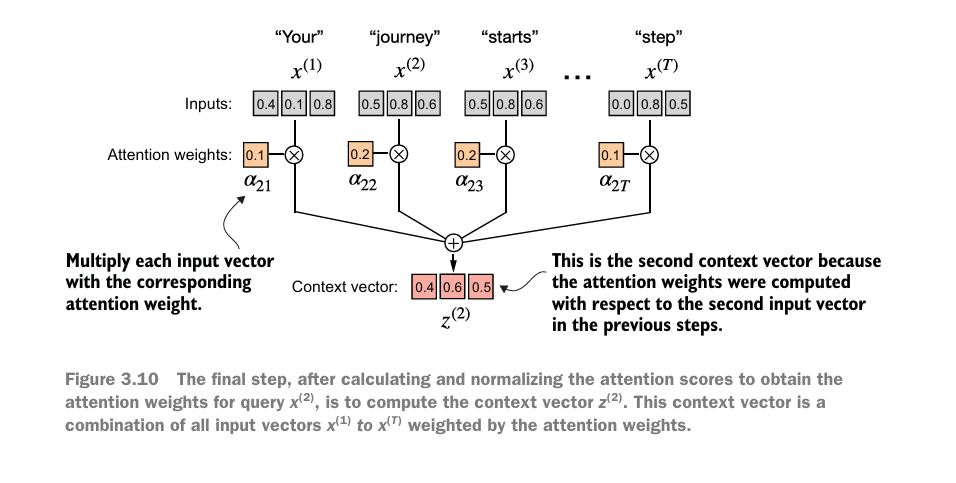

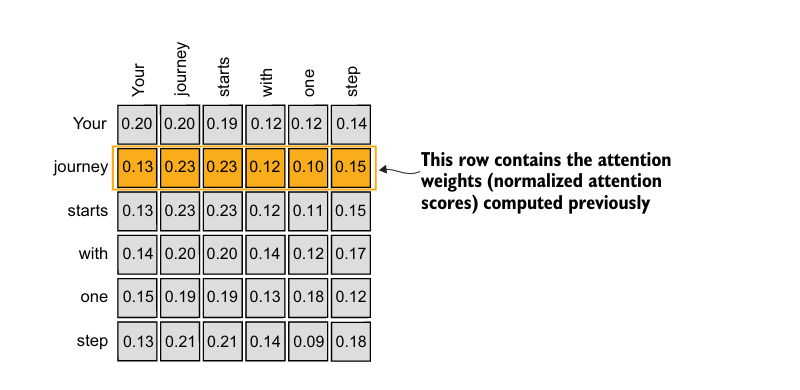

In [5]:
query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs): 
    context_vec_2 += attn_score_2_torch[i] * x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


### Dot Product Formulation  

In [6]:
attn_score = torch.empty(6,6)
for i , x_i in enumerate(inputs): 
    for j , x_j in enumerate(inputs):
        attn_score[i,j] = torch.dot(x_i , x_j)
print(attn_score)
print(sum(attn_score[0]))

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])
tensor(4.4600)


In [7]:
attn_score = inputs @ inputs.T 
attn_weight = torch.softmax(attn_score, dim=-1)
sum(attn_weight[0])

tensor(1.0000)

In [8]:
all_context_vecs = attn_weight @ inputs
all_context_vecs

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])

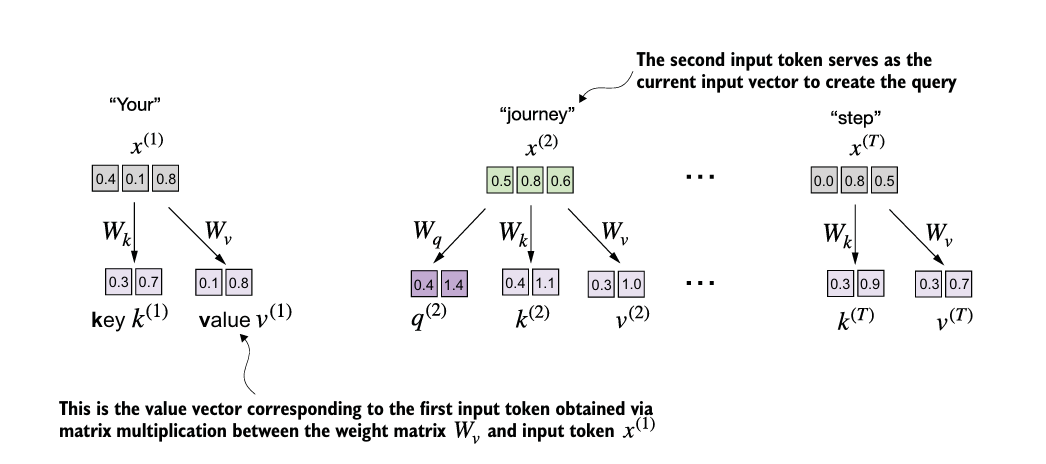

In [9]:
# usually input and ouput dimensions of the projections are the same 
x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2 

In [10]:
w_query = torch.nn.Parameter(torch.rand(d_in , d_out) , requires_grad=False)
w_key = torch.nn.Parameter(torch.rand(d_in , d_out) , requires_grad=False)
w_value = torch.nn.Parameter(torch.rand(d_in , d_out) , requires_grad=False)
# grad set as false just for convinence during training should be true
query_2 = x_2 @ w_query 
key_2 = x_2 @ w_key 
value_2 = x_2 @ w_value 

print(query_2)


tensor([0.9123, 1.1811])


In [11]:
query_2 @ key_2

tensor(1.9809)

In [12]:
query = inputs  @ w_query
keys = inputs @ w_key 
values = inputs @ w_value
print("query.shape:", query.shape)
print("keys.shape:", keys.shape)
print("values.shape:", values.shape)

query.shape: torch.Size([6, 2])
keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])


In [13]:
key_2 = keys[1]
attn_score_22 = query_2.dot(key_2)
print(attn_score_22)

tensor(1.9809)


In [14]:
attn_score_2 = query_2 @ keys.T
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_score_2 / d_k**0.5 , dim=-1)
print(attn_weights_2)

tensor([0.1471, 0.2313, 0.2293, 0.1211, 0.1328, 0.1385])


In [15]:
# we use Linear here instead of Parameter 
import torch.nn as nn 

class selfAttention_v1(nn.Module): 

    def __init__(self , d_in , d_out): 
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in , d_out))
        self.W_key = nn.Parameter(torch.rand(d_in , d_out))
        self.W_value = nn.Parameter(torch.rand(d_in , d_out))

    def forward(self , x): 

        keys = x @ self.W_query
        query = x @ self.W_key
        values = x @ self.W_value
        attn_score = query @ keys.T 
        attn_weights = torch.softmax(attn_score / keys.shape[-1]**0.5 , dim=-1)
        context_vec = attn_weights @ values 
        return context_vec 
    

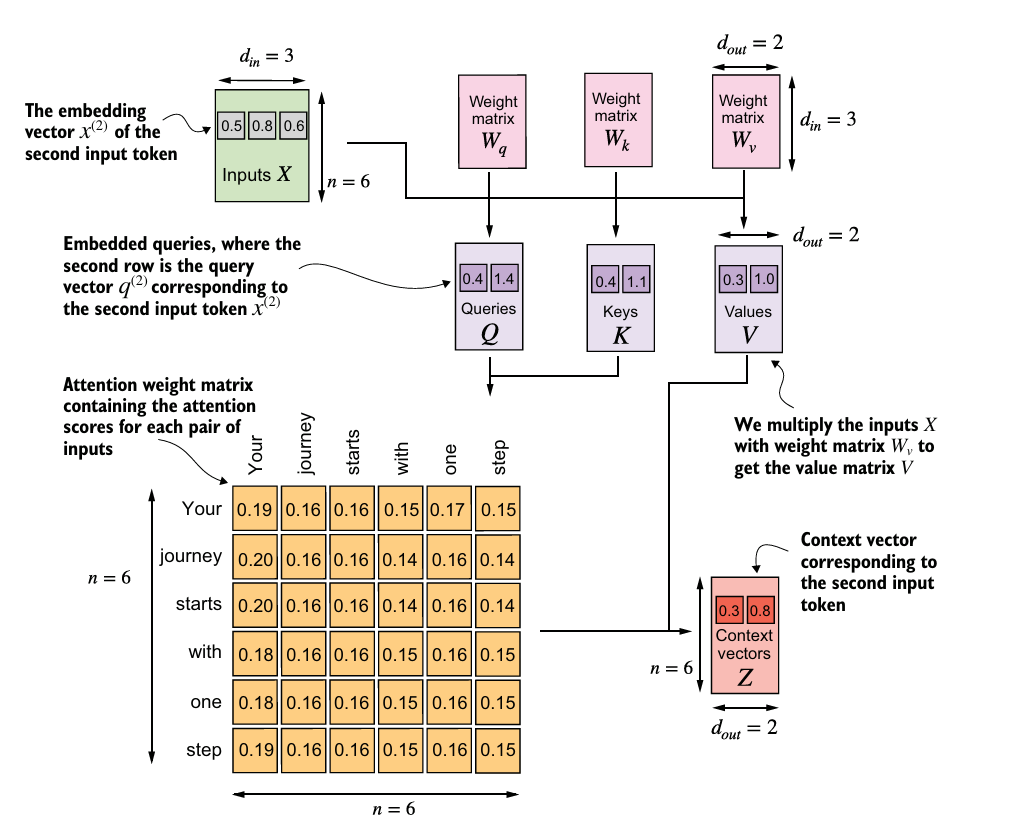

In [16]:
torch.manual_seed(123) 
sa_v1= selfAttention_v1(d_in , d_out)
print(sa_v1(inputs))

tensor([[0.2947, 0.7956],
        [0.3015, 0.8132],
        [0.3010, 0.8120],
        [0.2925, 0.7902],
        [0.2863, 0.7737],
        [0.2979, 0.8043]], grad_fn=<MmBackward0>)


In [17]:
class selfAttention_v2(nn.Module):

    def __init__(self , d_in , d_out, qkv_bias= False): 
       super().__init__()
       self.w_query = nn.Linear(d_in , d_out, bias=qkv_bias)
       self.w_key = nn.Linear(d_in , d_out, bias=qkv_bias)
       self.w_value = nn.Linear(d_in , d_out, bias=qkv_bias)

    def forward(self , x): 
        key = self.w_key(x)
        query =self.w_query(x)
        value =  self.w_value(x)
        attn_scores = query @ key.T
        attn_weights = torch.softmax(attn_scores/key.shape[-1]**0.5, dim=-1)
        context = attn_weights @ value 

        return context 

In [18]:
torch.manual_seed(789)
sa_v2 = selfAttention_v2(d_in , d_out)
sa_v2(inputs)   

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)

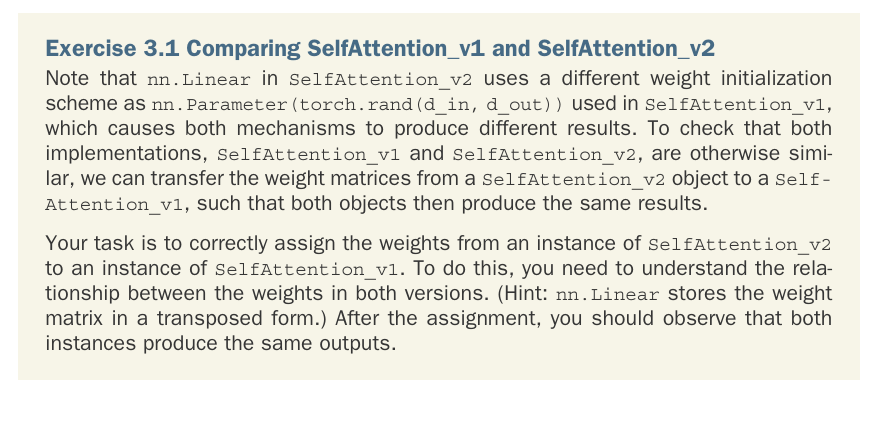

In [19]:
import torch.nn as nn 

class selfAttention_v3(nn.Module): 

    def __init__(self , d_in , d_out): 
        super().__init__()
        self.W_query = sa_v2.w_query
        self.W_key = sa_v2.w_key
        self.W_value = sa_v2.w_value

    def forward(self , x): 

        keys = x @ self.W_query
        query = x @ self.W_key
        values = x @ self.W_value
        attn_score = query @ keys.T 
        attn_weights = torch.softmax(attn_score / keys.shape[-1]**0.5 , dim=-1)
        context_vec = attn_weights @ values 
        return context_vec 
    

In [20]:
torch.manual_seed(789)
sa_v2 = selfAttention_v2(d_in , d_out)
sa_v2(inputs) 

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)

### Causal Attention

- Causal Attention is a masked form of attention which only allows access to previous tokens

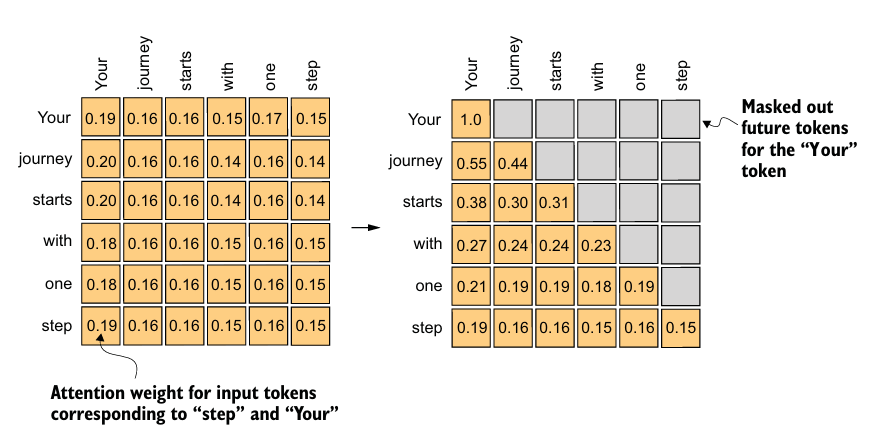

In [21]:
queries = sa_v2.w_query(inputs)    
keys = sa_v2.w_key(inputs) 
attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
print(attn_weights)

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


-  PyTorch’s tril function to create a mask
where the values above the diagonal are zero

In [22]:
context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length , context_length))
print(mask_simple)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [23]:
#multiple the mask with the attention scores to zero out the values 
masked_sample = attn_weights *  mask_simple
print(masked_sample)

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)


- The mathematical elegance of softmax is that despite initially including all positions
in the denominator, after masking and renormalizing, the effect of the masked posi
tions is nullified—they don’t contribute to the softmax score in any meaningful way.

- When we pass -inf into the softmax. it gives us - because exp(-inf) approaches zero. 

In [24]:
# normalize the rows now 
# there is no leakage from the previous softmax because we are essentiall redoing the soft max operation
row_sums = masked_sample.sum(dim=-1 , keepdim=True)
masked_simple_norm = masked_sample / row_sums
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)


In [25]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_score.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.9995,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.9544, 1.4950,   -inf,   -inf,   -inf,   -inf],
        [0.9422, 1.4754, 1.4570,   -inf,   -inf,   -inf],
        [0.4753, 0.8434, 0.8296, 0.4937,   -inf,   -inf],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654,   -inf],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [26]:
attn_weights = torch.softmax(masked / keys.shape[-1]**0.5 , dim=1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4056, 0.5944, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2566, 0.3741, 0.3693, 0.0000, 0.0000, 0.0000],
        [0.2176, 0.2823, 0.2796, 0.2205, 0.0000, 0.0000],
        [0.1826, 0.2178, 0.2191, 0.1689, 0.2115, 0.0000],
        [0.1473, 0.2033, 0.1996, 0.1500, 0.1160, 0.1839]])


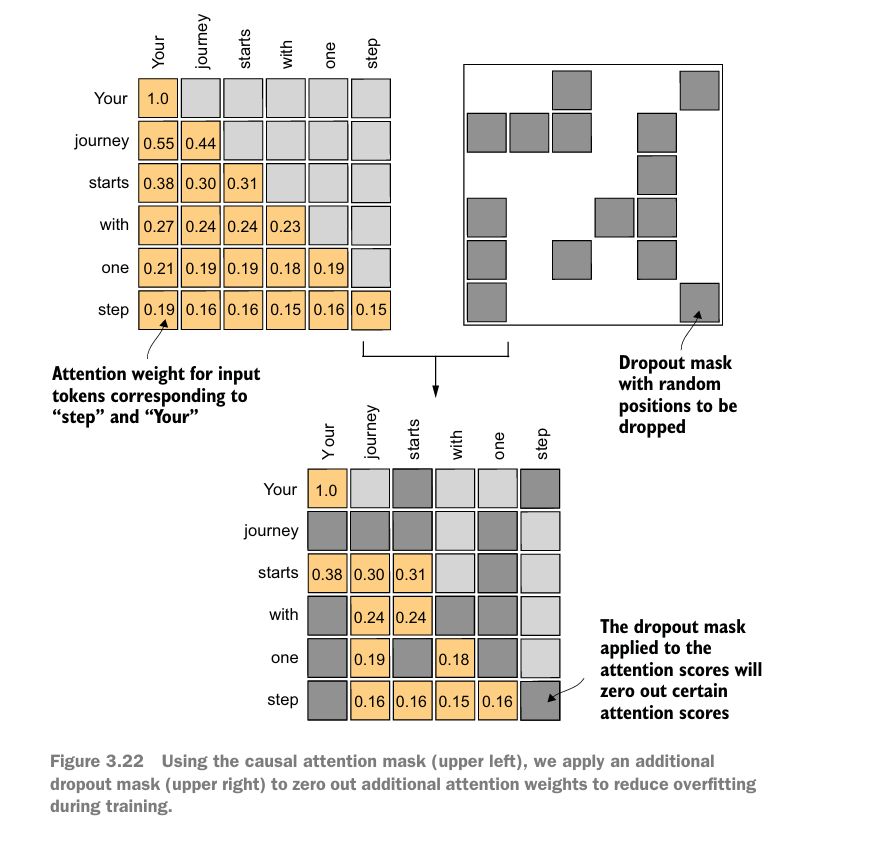

- Dropout 
  - After calculating attention weights
  - After Applying attention weights to the value vectors

In [27]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5)
example = torch.ones(6,6)
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


In [28]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5132, 0.7482, 0.7386, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.5646, 0.5592, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4357, 0.0000, 0.3378, 0.0000, 0.0000],
        [0.0000, 0.4065, 0.3991, 0.2999, 0.2320, 0.0000]])


In [29]:
batch = torch.stack((inputs ,  inputs) , dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


-  self
.register_buffer() call in the __init__ method. The use of register_buffer in
PyTorch is not strictly necessary for all use cases but offers several advantages here. For
instance, when we use the CausalAttention class in our LLM, buffers are automati
cally moved to the appropriate device (CPU or GPU) along with our model, which will
be relevant when training our LLM. This means we don’t need to manually ensure
these tensors are on the same device as your model parameters, avoiding device mis
match errors.

In [30]:
class CausalAttention(nn.Module): 
    def __init__(self , d_in , d_out , context_length , dropout , qkv_bias = False):
        super().__init__()
        self.d_out = d_out 
        self.w_query = nn.Linear(d_in , d_out , bias=qkv_bias)
        self.w_key = nn.Linear(d_in , d_out , bias = qkv_bias )
        self.w_value = nn.Linear(d_in , d_out , bias = qkv_bias )
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask" , torch.triu(torch.ones(context_length, context_length) , diagonal=1))

    def forward(self , x): 
        b , num_tokens , d_in = x.shape
        keys = self.w_key(x)
        queries = self.w_query(x)
        values = self.w_value(x)

        attn_scores = queries @ keys.transpose(1,2)
        attn_scores.masked_fill_(self.mask.bool()[:num_tokens,:num_tokens], -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = attn_weights @ values 
        return context_vec
    

In [31]:
torch.manual_seed(123)

context_length = batch.shape[1]
ca =  CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs = ca(batch)
print("context_vecs.shape:", context_vecs.shape)

context_vecs.shape: torch.Size([2, 6, 2])


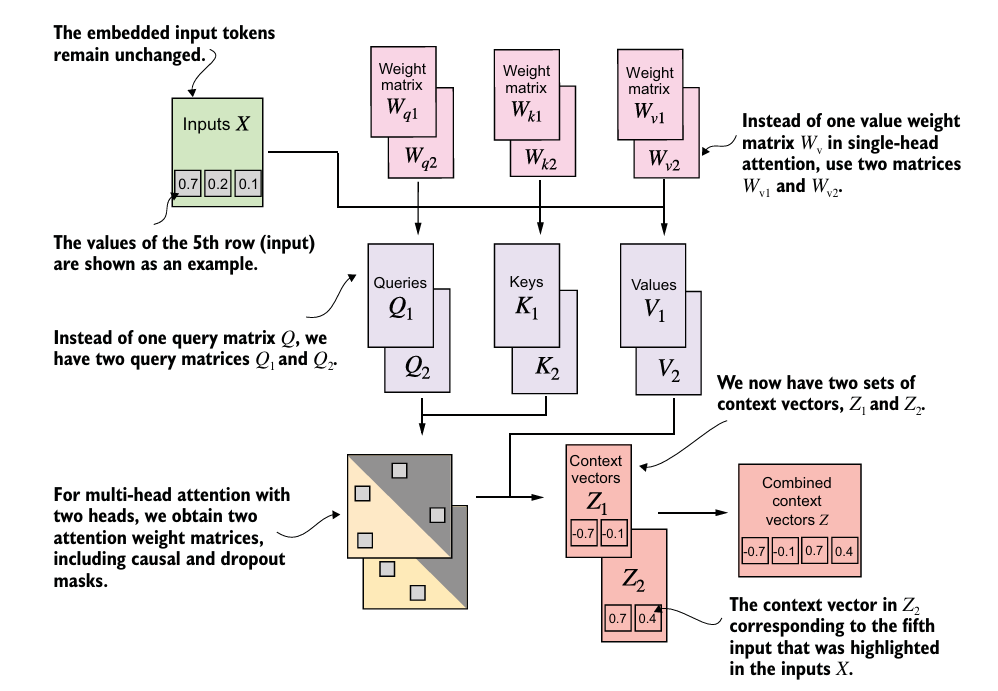

In [32]:
class MultiheadAttentionWrapper(nn.Module): 
    def __init__(self , d_in , d_out , context_length , dropout , num_heads , qkv_bias = False):
        super().__init__()
        self.heads = nn.ModuleList([CausalAttention(  d_in, d_out, context_length, dropout, qkv_bias) for _ in range(num_heads)])

    def forward(self , x): 
            return torch.concat([head(x) for head in self.heads] , dim=-1)
        

In [33]:
torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens
d_in, d_out = 3, 2
mha = MultiheadAttentionWrapper(
    d_in, d_out, context_length, 0.0, num_heads=2
)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.4519,  0.2216,  0.4772,  0.1063],
         [-0.5874,  0.0058,  0.5891,  0.3257],
         [-0.6300, -0.0632,  0.6202,  0.3860],
         [-0.5675, -0.0843,  0.5478,  0.3589],
         [-0.5526, -0.0981,  0.5321,  0.3428],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.4519,  0.2216,  0.4772,  0.1063],
         [-0.5874,  0.0058,  0.5891,  0.3257],
         [-0.6300, -0.0632,  0.6202,  0.3860],
         [-0.5675, -0.0843,  0.5478,  0.3589],
         [-0.5526, -0.0981,  0.5321,  0.3428],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


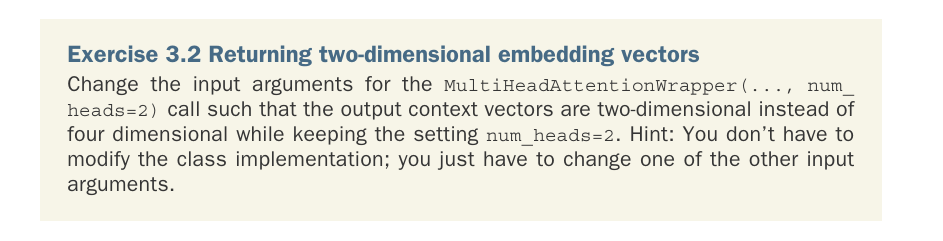

In [34]:
torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens

mha_1 = MultiheadAttentionWrapper(
    3, 1, context_length   , 0.0, num_heads=2
)
context_vecs_1 = mha_1(batch)
print(context_vecs_1)
print("context_vecs.shape:", context_vecs_1.shape)

tensor([[[-0.5740,  0.2216],
         [-0.7320,  0.0155],
         [-0.7774, -0.0546],
         [-0.6979, -0.0817],
         [-0.6538, -0.0957],
         [-0.6424, -0.1065]],

        [[-0.5740,  0.2216],
         [-0.7320,  0.0155],
         [-0.7774, -0.0546],
         [-0.6979, -0.0817],
         [-0.6538, -0.0957],
         [-0.6424, -0.1065]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


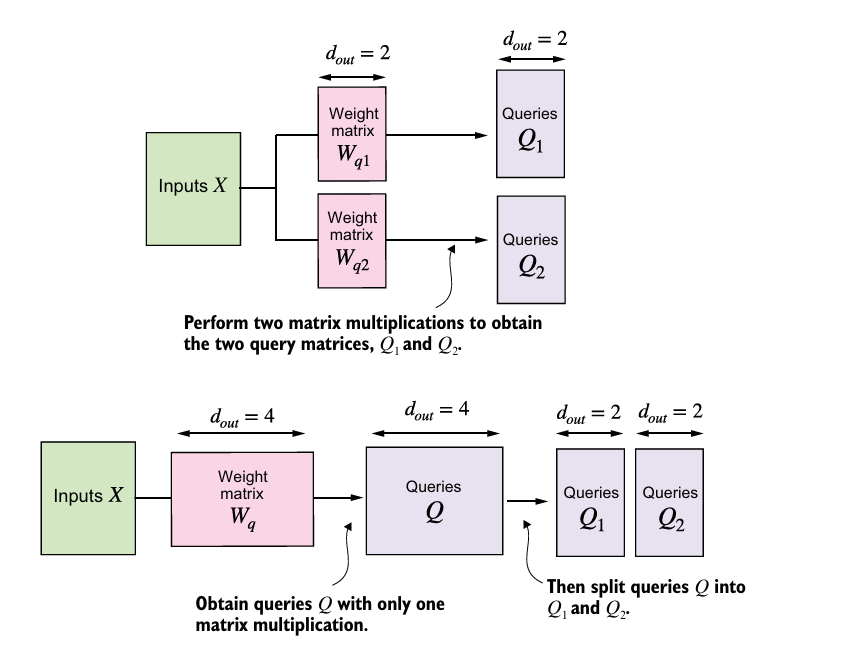

In [63]:
class MultiheadAttention(nn.Module): 
    def __init__(self , d_in , d_out , context_length , dropout , num_heads , qkv_bias =True):
        super().__init__()
        assert (d_out % num_heads == 0) ,  "d_out must be divisible by num_heads"
        self.d_out = d_out 
        self.num_heads = num_heads 
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)   
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                    diagonal=1))

    def forward(self ,x): 
        b , num_tokens , d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        keys = keys.view(b , num_tokens , self.num_heads , self.head_dim)
        values = values.view(b , num_tokens , self.num_heads , self.head_dim)
        queries = queries.view(b , num_tokens , self.num_heads , self.head_dim)
        keys = keys.transpose(1,2)
        queries = queries.transpose(1,2)
        values = values.transpose(1,2)
        attn_scores = queries @ keys.transpose(2,3)
        mask_bool = self.mask.bool()[:num_tokens , :num_tokens]
        attn_scores.masked_fill(mask_bool , -torch.inf)

        attn_weight = torch.softmax(attn_scores / keys.shape[-1]**0.5 , dim=-1)
        attn_weight =self.dropout(attn_weight)

        context_vec = (attn_weight @values).transpose(1,2)
        context_vec =  context_vec.contiguous().view(
        b, num_tokens, self.d_out
            )
        context_vec = self.out_proj(context_vec)   
        return context_vec



In [48]:
# batch X num_heads  num_tokens X head_dim
a = torch.tensor([[[[0.2745, 0.6584, 0.2775, 0.8573],   
            [0.8993, 0.0390, 0.9268, 0.7388],
            [0.7179, 0.7058, 0.9156, 0.4340]],
           [[0.0772, 0.3565, 0.1479, 0.5331],
            [0.4066, 0.2318, 0.4545, 0.9737],
            [0.4606, 0.5159, 0.4220, 0.5786]]]])
a.shape

torch.Size([1, 2, 3, 4])

In [49]:
print(a @ a.transpose(2, 3))
print((a @ a.transpose(2, 3)).shape)

tensor([[[[1.3208, 1.1631, 1.2879],
          [1.1631, 2.2150, 1.8424],
          [1.2879, 1.8424, 2.0402]],

         [[0.4391, 0.7003, 0.5903],
          [0.7003, 1.3737, 1.0620],
          [0.5903, 1.0620, 0.9912]]]])
torch.Size([1, 2, 3, 3])


In [50]:
torch.manual_seed(123)
batch_size, context_length, d_in = batch.shape
d_out = 2
mha = MultiheadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[ 0.7732, -0.2205],
         [ 0.7645, -0.1799],
         [ 0.7633, -0.1693],
         [ 0.7462, -0.1963],
         [ 0.7536, -0.1992],
         [ 0.7348, -0.2132]],

        [[ 0.7732, -0.2205],
         [ 0.7645, -0.1799],
         [ 0.7633, -0.1693],
         [ 0.7462, -0.1963],
         [ 0.7536, -0.1992],
         [ 0.7348, -0.2132]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


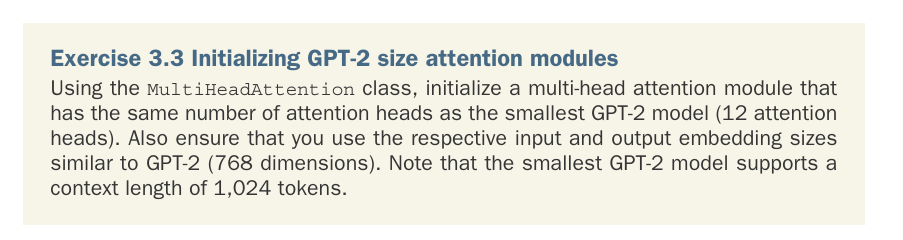

In [64]:
torch.manual_seed(123)
batch = torch.randn(2, 1024, 768)
batch_size, context_length, d_in = batch.shape
d_out = 768
mha = MultiheadAttention(d_in, d_out, context_length, 0.0, num_heads=12)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.0208, -0.0385, -0.0293,  ..., -0.0247, -0.0685,  0.0230],
         [-0.0139, -0.0343, -0.0343,  ..., -0.0186, -0.0642,  0.0221],
         [-0.0174, -0.0369, -0.0214,  ..., -0.0198, -0.0662,  0.0256],
         ...,
         [-0.0153, -0.0402, -0.0309,  ..., -0.0251, -0.0550,  0.0181],
         [-0.0193, -0.0299, -0.0263,  ..., -0.0266, -0.0606,  0.0199],
         [-0.0194, -0.0322, -0.0209,  ..., -0.0263, -0.0529,  0.0271]],

        [[-0.0314, -0.0249, -0.0313,  ..., -0.0384, -0.0284,  0.0254],
         [-0.0309, -0.0206, -0.0291,  ..., -0.0377, -0.0314,  0.0338],
         [-0.0323, -0.0248, -0.0305,  ..., -0.0365, -0.0227,  0.0357],
         ...,
         [-0.0311, -0.0187, -0.0272,  ..., -0.0361, -0.0346,  0.0224],
         [-0.0277, -0.0367, -0.0289,  ..., -0.0386, -0.0417,  0.0201],
         [-0.0266, -0.0251, -0.0323,  ..., -0.0448, -0.0339,  0.0335]]],
       grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 1024, 768])
